<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h1 style="color:#0F2A4A">نوت‌بوک ۴ — ماشین بردار پشتیبان</h1>
<h2 style="color:#0E7490">Support Vector Machine (SVM)</h2>
<p>SVM ابرصفحه جداکننده‌ای انتخاب می‌کند که <b>بزرگ‌ترین حاشیه (Margin)</b> را بین دو کلاس بسازد. نمونه‌های روی لبه حاشیه = <b>بردارهای پشتیبان</b>.</p>
<p>در این نوت‌بوک:</p>
<ul><li>SVM خطی با رسم حاشیه روی دو کلاس Iris</li><li>داده غیرخطی (حلقه‌ها) و قدرت کرنل RBF</li><li>اثر پارامتر C</li></ul>
<p style="color:#45607A; font-size:13px">همراه ارائه درس «داده‌کاوی و یادگیری ماشین» — برای اجرا در Google Colab: هر سلول را با <b>Shift+Enter</b> اجرا کنید و پارامترها را آزادانه تغییر دهید.</p>
<hr style="border:0;border-top:1px dashed #B7DFEA;margin:10px 0">
<p style="background:#EBF7FA;border:1px solid #B7DFEA;border-radius:8px;padding:10px 12px">
🛠 <b>راهنمای استفاده:</b> همهٔ کدها در <b>Google Colab</b> اجرا می‌شوند — بدون نصبِ پایتون یا کتابخانه؛ فقط مرورگر و اینترنت (اجرای هر سلول: <b>Shift+Enter</b> یا منوی Runtime ▸ Run all).<br>
🐍 <b>یادگیری پایتون، از صفر:</b> <a href="https://www.w3schools.com/python/default.asp">W3Schools — Python Tutorial</a> — آموزش تعاملی و رایگان؛ مثال‌ها را همان‌جا اجرا و ویرایش کنید.<br>
📝 <b>هر سلول:</b> توضیح فارسی در بالای سلول و کامنت‌های فارسی داخل کد آمده است؛ خروجی‌ها هم از قبل ذخیره شده‌اند.
</p>
</div>

In [1]:
# تنظیمات اولیه: واردکردن کتابخانه‌ها + پالت رنگی و ظاهر یکسان نمودارها
import numpy as np, pandas as pd, matplotlib.pyplot as plt
TEAL, NAVY, AMBER = "#0E7490", "#0F2A4A", "#B45309"
plt.rcParams.update({"figure.facecolor":"white","axes.grid":True,"grid.color":"#D8E2EC",
    "axes.edgecolor":"#94A3B8","axes.labelcolor":"#0F2A4A","text.color":"#0F2A4A",
    "axes.titlecolor":"#0F2A4A","axes.titleweight":"bold","legend.frameon":False,
    "xtick.color":"#334155","ytick.color":"#334155"})
print("libraries ready")

libraries ready


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۱) SVM خطی روی دو کلاس Iris</h2>
<p>دقت کنید: SVM به مقیاس حساس است → اول <code>StandardScaler</code>.</p>
</div>

In [2]:
# SVM خطی روی دو کلاسِ Iris (setosa حذف شده) — حتماً با StandardScaler
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

X, y = load_iris(return_X_y=True)
m = y != 0                       # versicolor + virginica
X2, y2 = X[:, 2:4][m], y[m]
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y2, test_size=.15,
                                              random_state=42, stratify=y2)
sc = StandardScaler().fit(X2_tr)
svm = SVC(kernel="linear", C=1.0).fit(sc.transform(X2_tr), y2_tr)
print("Test accuracy:", svm.score(sc.transform(X2_te), y2_te))
print("support vectors:", svm.n_support_.sum())

Test accuracy: 0.8
support vectors: 12


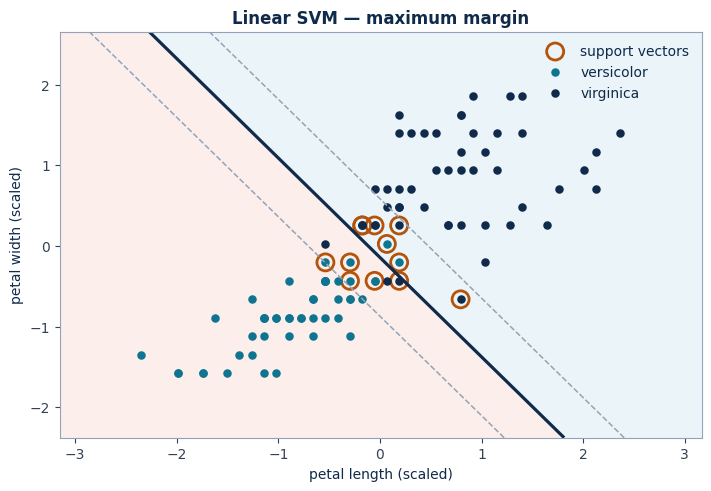

In [3]:
# ترسیم حداکثر حاشیه: خط مشکی مرز تصمیم، خط‌چین‌ها حاشیه، دایره‌های زرد = بردارهای پشتیبان
Z = sc.transform(X2)
fig, ax = plt.subplots(figsize=(7,4.8), layout="constrained")
xx, yy = np.meshgrid(np.linspace(Z[:,0].min()-.8, Z[:,0].max()+.8, 400),
                     np.linspace(Z[:,1].min()-.8, Z[:,1].max()+.8, 400))
dec = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax.contourf(xx, yy, dec>0, alpha=.13, cmap="RdBu")
ax.contour(xx, yy, dec, levels=[-1,0,1], linestyles=["--","-","--"],
           colors=["#94A3B8","#0F2A4A","#94A3B8"], linewidths=[1.1,2.3,1.1])
sv = svm.support_vectors_
ax.scatter(sv[:,0], sv[:,1], s=150, facecolors="none", edgecolors=AMBER,
           linewidths=2, label="support vectors")
for c, col in [(1,TEAL),(2,NAVY)]:
    s = y2==c; ax.scatter(Z[s,0], Z[s,1], c=col, s=26, label=load_iris().target_names[c])
ax.set_xlabel("petal length (scaled)"); ax.set_ylabel("petal width (scaled)")
ax.set_title("Linear SVM — maximum margin"); ax.legend(); ax.grid(False)
plt.show()

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۲) داده غیرخطی و کرنل RBF</h2>
<p>داده حلقه‌ای با خط جدا نمی‌شود؛ کرنل داده را به فضای با بعد بالاتر می‌برد (مبحث SVM غیرخطی اسلاید درس).</p>
</div>

In [4]:
# دادهٔ غیرخطی (دو حلقه): SVM خطی ۵۰٪ می‌ماند، هستهٔ RBF آن را کامل جدا می‌کند
from sklearn.datasets import make_circles
Xc, yc = make_circles(300, noise=.07, factor=.42, random_state=42)
sc2 = StandardScaler().fit(Xc)
lin = SVC(kernel="linear").fit(sc2.transform(Xc), yc)
rbf = SVC(kernel="rbf", C=10, gamma=1).fit(sc2.transform(Xc), yc)
print("linear accuracy:", lin.score(sc2.transform(Xc), yc))
print("RBF    accuracy:", rbf.score(sc2.transform(Xc), yc))

linear accuracy: 0.5933333333333334
RBF    accuracy: 1.0


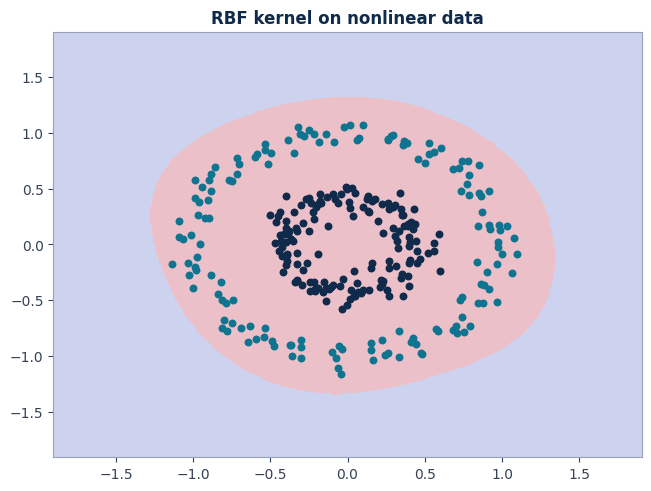

In [5]:
# ترسیم مرز غیرخطیِ هستهٔ RBF روی دادهٔ دو حلقه‌ای — خطی جواب نمی‌داد
fig, ax = plt.subplots(figsize=(6.4,4.8), layout="constrained")
xx, yy = np.meshgrid(np.linspace(-1.9,1.9,400), np.linspace(-1.9,1.9,400))
Zc = rbf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax.pcolormesh(xx, yy, Zc, cmap="coolwarm", alpha=.25, shading="auto")
ax.scatter(Xc[yc==0,0], Xc[yc==0,1], c=TEAL, s=22)
ax.scatter(Xc[yc==1,0], Xc[yc==1,1], c=NAVY, s=22)
ax.set_title("RBF kernel on nonlinear data"); ax.grid(False)
plt.show()

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۳) اثر پارامتر C</h2>
</div>

In [6]:
# نقش پارامتر C: C کوچک = حاشیهٔ ساده‌تر، C بزرگ = حساس‌تر (شبیه بیش‌برازش)
for C in [0.01, 1, 100]:
    s = SVC(kernel="rbf", C=C).fit(sc2.transform(Xc), yc)
    print(f"C={C:>6}: train acc = {s.score(sc2.transform(Xc), yc):.2f}, "
          f"n_support = {s.n_support_.sum()}")

C=  0.01: train acc = 1.00, n_support = 300
C=     1: train acc = 1.00, n_support = 32
C=   100: train acc = 1.00, n_support = 13


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">جمع‌بندی</h2>
<ul><li>SVM فقط به بردارهای پشتیبان نزدیک مرز اهمیت می‌دهد</li><li>کرنل RBF داده غیرخطی را قابل جداسازی می‌کند (اینجا: ~۵۹٪ → ۱۰۰٪)</li><li>C بزرگ = خطای آموزش کمتر ولی خطر بیش‌برازش</li></ul>
<p style="color:#45607A">قدم بعدی: پارامترها (مثل k یا max_depth) را تغییر دهید و اثرشان را روی خروجی ببینید.</p>
</div>